# Intent leakage and verified rewrites

A quantum program has to be transpiled to the backend's native gates and connectivity, and the resulting physical circuit is visible to whoever runs it. Buesser & Kurmus (IBM Research, QCE 2026) show that the structure of that circuit can reveal which kind of algorithm it implements.

This notebook uses our own implementation of that setting (47 generators in 7 algorithm classes, FakeNighthawk, 24 and 48 qubits, optimization levels 0-3) and covers:

1. an attacker classifying one compiled circuit,
2. semantics-preserving rewrites of that circuit, each checked for equivalence,
3. selecting a rewrite under an overhead budget and attacking it again,
4. equivalence checks and attack accuracy over the whole dataset,
5. defense results against attackers retrained on protected circuits.

Everything below reads the saved dataset and result files in `artifacts/paper_full`.

## Setup

In [1]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from qpf import compilation, defenses, verification, paper_circuits as PC, paper_benchmark as PB
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

cfg = PB.load_cfg("full"); BE = cfg["backend"]; FEAT = PB.FEAT          # FEAT = the 10 Table II features
GEN, VARIANT, N, OPT, BUDGET = "qft_swaps", 5, 24, 3, 0.20
LAB = {c: c.replace("_", " ") for c in PC.CLASS_LABELS}

ds = pd.read_csv(ROOT / "artifacts/paper_full/features/dataset.csv")
ds = ds[(ds.status == "OK") & (ds.n_qubits == N) & (ds.opt == OPT)]
truth, sid = PC.GENERATORS[GEN], PC.source_id(GEN, VARIANT)
train = ds[ds.source_id != sid]                                          # target source circuit left out
atk = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)).fit(train[FEAT].to_numpy(float), train.intent)
print(f"Attacker trained on {len(train)} compiled circuits ({train.source_id.nunique()} source circuits, {train.intent.nunique()} algorithm classes).")
print(f"Backend: {BE} | features: the 10 Table II features | target source circuit left out of training")

Attacker trained on 281 compiled circuits (281 source circuits, 7 algorithm classes).
Backend: FakeNighthawk | features: the 10 Table II features | target source circuit left out of training


## 1. Attack on an unprotected circuit
A 24-qubit QFT circuit is compiled for the backend. The attacker sees only the compiled circuit.

True class: fourier like
Compiled circuit: depth=942, two-qubit gates=869, active qubits=24
Prediction: 'fourier like' with 100% confidence (correct)


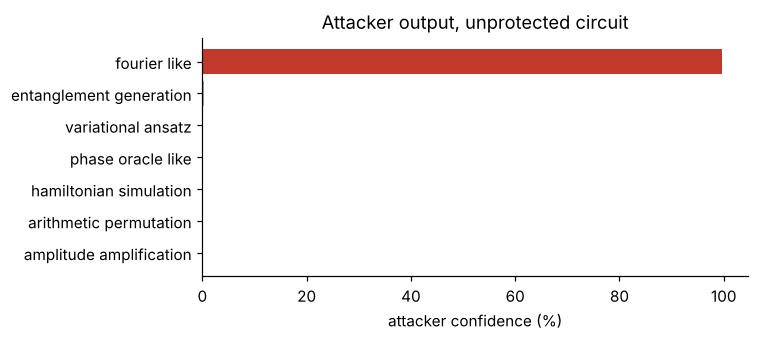

In [2]:
base = PC.make_source(GEN, N, VARIANT)
tc0, _ = compilation.compile_circuit(base, OPT, cfg["transpile_seed"], None, BE)
r0 = PB.physical_row(tc0, BE)
probs = dict(zip(atk.classes_, atk.predict_proba(np.array([[r0[f] for f in FEAT]], float))[0]))
pred = max(probs, key=probs.get); conf0 = probs[pred]
print(f"True class: {LAB[truth]}")
print(f"Compiled circuit: depth={r0['depth']}, two-qubit gates={r0['n2q']}, active qubits={r0['active']}")
print(f"Prediction: '{LAB[pred]}' with {conf0:.0%} confidence ({'correct' if pred == truth else 'incorrect'})")
order = sorted(probs, key=probs.get)
fig, ax = plt.subplots(figsize=(7, 3.2)); ax.barh([LAB[c] for c in order], [probs[c] * 100 for c in order], color=["#c0392b" if c == truth else "#9aa5b1" for c in order])
ax.set_xlabel("attacker confidence (%)"); ax.set_title("Attacker output, unprotected circuit"); plt.tight_layout(); plt.show()

## 2. Rewrite candidates and equivalence checks
Seven strategies (layout, transpiler seed, gate decomposition, commuting-gate reordering and combinations), three seeds each. A candidate is kept only if it passes an equivalence check (MQT QCEC, operator comparison or an identical-DAG check). Candidates above the 20% overhead budget are excluded from selection.

In [3]:
rows = []; t0 = time.perf_counter()
for si, st in enumerate(cfg["defense"]["strategies"]):
    for k in range(3):
        cseed = 1000 * (si + 1) + k + 1
        cand, layout = defenses.apply_strategy(base, st, cseed, BE)
        v = verification.verify(base, cand, operator_max_qubits=10, qcec_timeout_s=cfg["defense"]["qcec_timeout_s"])
        if v.status != "PASS":
            rows.append(dict(strategy=st, seed=k, verified=f"REJECTED ({v.status})", d_depth=np.nan, d_2q=np.nan, conf=np.nan, ok=False)); continue
        tc, _ = compilation.compile_circuit(cand, OPT, cfg["transpile_seed"] if "seed" not in st.split("+") else int(cseed % 100000) + 1, layout, BE)
        r = PB.physical_row(tc, BE); dd = r["depth"] / r0["depth"] - 1; d2 = r["n2q"] / r0["n2q"] - 1
        p = dict(zip(atk.classes_, atk.predict_proba(np.array([[r[f] for f in FEAT]], float))[0]))
        rows.append(dict(strategy=st, seed=k, verified=f"PASS ({v.method})", d_depth=dd, d_2q=d2, conf=p[pred], pred=max(p, key=p.get), ok=max(dd, d2) <= BUDGET))
T = pd.DataFrame(rows)
show = T.assign(d_depth=T.d_depth.map("{:+.1%}".format), d_2q=T.d_2q.map("{:+.1%}".format), conf=T.conf.map("{:.0%}".format), within_20pct_budget=T.ok.map({True: "yes", False: "NO"}))
display(show[["strategy", "seed", "verified", "d_depth", "d_2q", "conf", "within_20pct_budget"]])
print(f"{len(T)} candidates in {time.perf_counter() - t0:.0f}s: {int(T.verified.str.startswith('PASS').sum())} verified equivalent, {int((~T.verified.str.startswith('PASS')).sum())} rejected")

,strategy,seed,verified,d_depth,d_2q,conf,within_20pct_budget
0,layout,0,PASS (identical_logical_circuit),+25.2%,+34.8%,41%,NO
1,layout,1,PASS (identical_logical_circuit),+34.7%,+30.7%,48%,NO
2,layout,2,PASS (identical_logical_circuit),+20.2%,+24.9%,61%,NO
3,decomp,0,PASS (mqt_qcec),+1.4%,+15.2%,76%,yes
4,decomp,1,PASS (mqt_qcec),-4.5%,+16.2%,63%,yes
5,decomp,2,PASS (mqt_qcec),-7.4%,+11.9%,67%,yes
6,reorder,0,PASS (dag_identity),+0.0%,+0.0%,100%,yes
7,reorder,1,PASS (dag_identity),+0.0%,+0.0%,100%,yes
8,reorder,2,PASS (dag_identity),+0.0%,+0.0%,100%,yes
9,decomp+reorder,0,PASS (mqt_qcec),+14.1%,+19.3%,60%,yes


21 candidates in 5s: 21 verified equivalent, 0 rejected


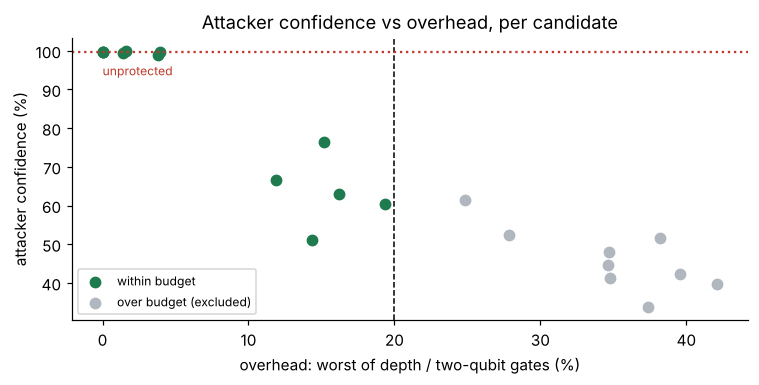

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6)); ov = T[["d_depth", "d_2q"]].max(axis=1) * 100
ax.scatter(ov[T.ok], T.conf[T.ok] * 100, c="#1f7a4d", label="within budget", s=45); ax.scatter(ov[~T.ok], T.conf[~T.ok] * 100, c="#b0b7bf", label="over budget (excluded)", s=45)
ax.axvline(BUDGET * 100, ls="--", c="k", lw=1); ax.axhline(conf0 * 100, ls=":", c="#c0392b"); ax.text(ov.min(), conf0 * 100 - 6, "unprotected", color="#c0392b", fontsize=8)
ax.set_xlabel("overhead: worst of depth / two-qubit gates (%)"); ax.set_ylabel("attacker confidence (%)"); ax.set_title("Attacker confidence vs overhead, per candidate"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Selection under the overhead budget
Selection does not use the label: it takes the verified, in-budget candidate with the lowest attacker confidence in its original guess.

Selected: decomp+reorder (seed 2) | depth -9.9% | two-qubit gates +14.4% | equivalence: PASS (mqt_qcec)
Attacker confidence in its original guess: 100% -> 51%
Prediction on the rewritten circuit: unchanged


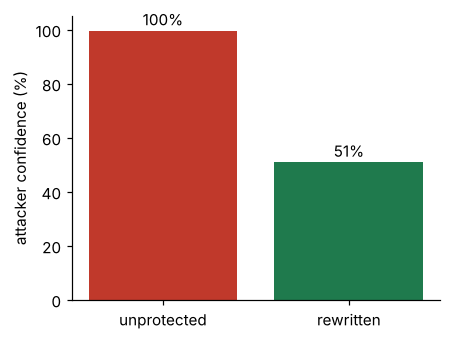

In [5]:
elig = T[T.verified.str.startswith("PASS") & T.ok]
if elig.empty: print("No verified candidate within budget; the unprotected circuit is kept.")
else:
    b = elig.sort_values("conf").iloc[0]
    print(f"Selected: {b.strategy} (seed {int(b.seed)}) | depth {b.d_depth:+.1%} | two-qubit gates {b.d_2q:+.1%} | equivalence: {b.verified}")
    print(f"Attacker confidence in its original guess: {conf0:.0%} -> {b.conf:.0%}")
    print("Prediction on the rewritten circuit:", "unchanged" if b["pred"] == truth else "changed")
    fig, ax = plt.subplots(figsize=(4.2, 3.2)); ax.bar(["unprotected", "rewritten"], [conf0 * 100, b.conf * 100], color=["#c0392b", "#1f7a4d"])
    ax.set_ylabel("attacker confidence (%)"); ax.set_ylim(0, 105); [ax.text(i, v + 2, f"{v:.0f}%", ha="center") for i, v in enumerate([conf0 * 100, b.conf * 100])]; plt.tight_layout(); plt.show()

## 4. Equivalence checks over all candidates
The previous sections use one circuit. This covers every candidate in the defense run: 282 source circuits x 7 strategies.

In [6]:
cand = pd.read_csv(ROOT / "artifacts/paper_full/defense/candidates.csv").drop_duplicates("cid")        # one row per unique candidate circuit
print(f"{len(cand)} unique candidate circuits | all verified equivalent: {bool((cand.verify_status == 'PASS').all())}")
display(cand.groupby(["verify_status", "verify_method"]).size().rename("count").reset_index())

1974 unique candidate circuits | all verified equivalent: True


,verify_status,verify_method,count
0,PASS,dag_identity,564
1,PASS,identical_logical_circuit,564
2,PASS,mqt_qcec,846


## 5. Attack accuracy across optimization levels
Accuracy of the paper-style attacker trained on one optimization level (rows) and tested on another (columns), averaged over 5 source-disjoint splits. Chance level for 7 classes is about 0.14.

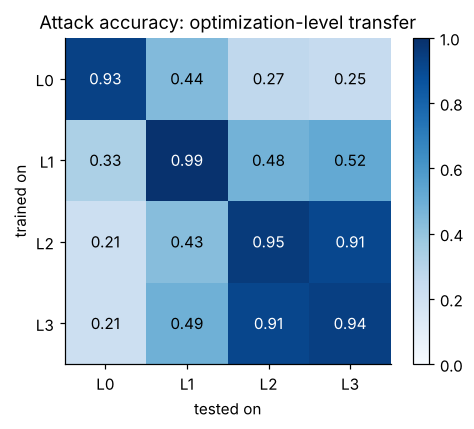

Matching settings: 0.93-0.99 accuracy | mismatched settings: 0.21-0.91 (L2<->L3 transfer is high: 0.91 / 0.91)


In [7]:
pc = pd.read_csv(ROOT / "artifacts/paper_full/results/paper_comparison.csv")
m = pc[(pc.matrix == "optimization_level") & (pc.metric == "accuracy")].copy(); m[["tr", "te"]] = m.train_test.str.split("->", expand=True)
M = m.pivot(index="tr", columns="te", values="ours_mean")
fig, ax = plt.subplots(figsize=(4.8, 4)); im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4), M.columns); ax.set_yticks(range(4), M.index); ax.set_xlabel("tested on"); ax.set_ylabel("trained on"); ax.set_title("Attack accuracy: optimization-level transfer")
[ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", color="white" if M.values[i, j] > .55 else "black") for i in range(4) for j in range(4)]
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
diag = np.diag(M.values); off = M.values[~np.eye(4, dtype=bool)]
print(f"Matching settings: {diag.min():.2f}-{diag.max():.2f} accuracy | mismatched settings: {off.min():.2f}-{off.max():.2f} (L2<->L3 transfer is high: {M.loc['L2','L3']:.2f} / {M.loc['L3','L2']:.2f})")

## 6. Defense results against retrained attackers
The attacker is retrained on protected circuits. Lower macro-F1 means less recoverable intent. Guided is the label-free selection above; random picks a random eligible candidate.

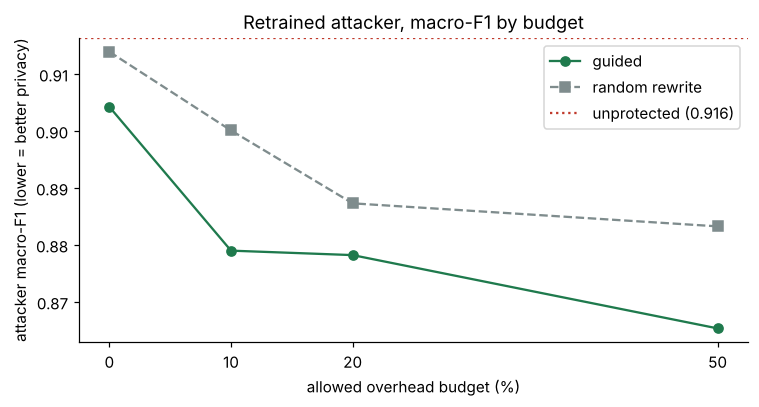

,unprotected,guided,random,drop (guided),95% CI low,95% CI high
0%,0.916,0.904,0.914,0.012,-0.006,0.030
10%,0.916,0.879,0.900,0.037,0.017,0.058
20%,0.916,0.878,0.887,0.038,0.017,0.059
50%,0.916,0.865,0.883,0.051,0.029,0.073


Best: 0.916 -> 0.865 at a 50% budget = 0.051 absolute drop (5.6% relative).


In [8]:
ds_ = pd.read_csv(ROOT / "artifacts/paper_full/results/defense_summary.csv")
ad = ds_[ds_.attacker == "adaptive_pooled"].pivot(index="budget", columns="arm", values="macro_f1_mean")
dl = ds_[ds_.attacker == "DELTA_adaptive_vs_unprotected_abs"].pivot(index="budget", columns="arm", values="macro_f1_mean")
base_f1 = float((ds_[(ds_.attacker == "adaptive_pooled") & (ds_.budget == .5) & (ds_.arm == "guided")].macro_f1_mean.iloc[0]) + dl.loc[.5, "guided"])
x = [b * 100 for b in ad.index]
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.plot(x, ad["guided"], "o-", c="#1f7a4d", label="guided"); ax.plot(x, ad["random"], "s--", c="#7f8c8d", label="random rewrite")
ax.axhline(base_f1, c="#c0392b", ls=":", label=f"unprotected ({base_f1:.3f})"); ax.set_xlabel("allowed overhead budget (%)"); ax.set_ylabel("attacker macro-F1 (lower = better privacy)")
ax.set_xticks(x); ax.set_title("Retrained attacker, macro-F1 by budget"); ax.legend(); plt.tight_layout(); plt.show()
ci = ds_[(ds_.attacker == "DELTA_adaptive_vs_unprotected_abs") & (ds_.arm == "guided")].set_index("budget")
out = pd.DataFrame({"unprotected": base_f1, "guided": ad["guided"], "random": ad["random"], "drop (guided)": ci.macro_f1_mean, "95% CI low": ci.ci_lo, "95% CI high": ci.ci_hi}).round(3); out.index = [f"{int(b*100)}%" for b in out.index]
display(out)
print(f"Best: {base_f1:.3f} -> {ad.loc[.5, 'guided']:.3f} at a 50% budget = {dl.loc[.5, 'guided']:.3f} absolute drop ({dl.loc[.5, 'guided'] / base_f1:.1%} relative).")

## Notes and limitations
- The attacker identifies the algorithm class from circuit structure alone.
- Rewrites are verified equivalent and within budget. Guided selection does better than random selection, but the drop in attacker macro-F1 is about 0.05 at the 50% budget; this is not a confidentiality guarantee.
- A classifier on circuit size and shape alone (no structural features) reaches about 0.94 accuracy, so part of the signal is plain size.
- Generators and feature conventions are our reading of the paper. Equivalence is checked on the logical rewrite at 24 qubits, not on the compiled circuit. All runs use the FakeNighthawk simulation.
- Open items: structure-hiding rewrites beyond what is tested here, and runs on real hardware.